# Apex Lark – Day 08: Advanced Data Cleaning & Data Transformation Using Pandas

**Author:** Kriti Ahlawat  |  **Program:** ApexLark Data Analytics Internship
**Tools:** Python, Pandas, NumPy, Matplotlib
**Dataset:** Sample Superstore retail sales (`data/superstore_sales_input.csv`), 9,993 order lines, Jan 2014 – Dec 2017

**Business scenario:** a retail company receives daily sales data from several branches. Before it can be used for reporting, it must be
profiled, cleaned, transformed into a standard format and analysed.

| # | Section |
|---|---|
| 1 | Setup & configuration |
| 2 | Load the dataset |
| 3 | Data quality assessment |
| 4 | Data cleaning |
| 5 | Data transformation (new business columns) |
| 6 | Exploratory data analysis |
| 7 | Data visualization |
| 8 | Save outputs & business insights |

## 1. Setup & configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

try:                       # `display` exists in Jupyter; fall back to print in a plain script
    display
except NameError:
    display = print

# ---- Paths -----------------------------------------------------------------
RAW_PATH = Path("data/superstore_sales_input.csv")
CLEAN_PATH = Path("data/superstore_sales_day08_cleaned.csv")
CHART_DIR = Path("charts")
OUTPUT_DIR = Path("outputs")
CHART_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# ---- Business rules (change here, everything else follows) -----------------
HIGH_MARGIN_PCT = 30      # profit margin >= 30%         -> "High"
MEDIUM_MARGIN_PCT = 10    # 10% <= margin < 30%          -> "Medium"; below 10% (incl. losses) -> "Low"
KEY_COLUMNS = ["order_id", "product_id"]   # rows missing these cannot be repaired

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

PRIMARY, ACCENT, GREY = "#2F5597", "#ED7D31", "#7F7F7F"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "axes.titlesize": 13})

money = FuncFormatter(lambda v, _: f"${v/1e6:.1f}M" if abs(v) >= 1e6 else f"${v/1e3:.0f}K" if abs(v) >= 1e3 else f"${v:.0f}")

_NEW_CHARTS = []           # (used by the notebook builder to embed saved charts)


def save_chart(fig, filename):
    """Save a figure to charts/ and close it."""
    path = CHART_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    _NEW_CHARTS.append(str(path))
    print(f"saved {path}")

## 2. Load the dataset

In [2]:
raw = pd.read_csv(RAW_PATH)
print("First 10 records")
display(raw.head(10))

First 10 records
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID    Segment        Country             City       State Region       Product ID  \
0       1  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   Consumer  United States        Henderson    Kentucky  South  FUR-BO-10001798   
1       2  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   Consumer  United States        Henderson    Kentucky  South  FUR-CH-10000454   
2       3  CA-2016-138688  2016-06-12  2016-06-16    Second Class    DV-13045  Corporate  United States      Los Angeles  California   West  OFF-LA-10000240   
3       4  US-2015-108966  2015-10-11  2015-10-18  Standard Class    SO-20335   Consumer  United States  Fort Lauderdale     Florida  South  FUR-TA-10000577   
4       5  US-2015-108966  2015-10-11  2015-10-18  Standard Class    SO-20335   Consumer  United States  Fort Lauderdale     Florida  South  OFF-ST-10000760   
5       6  CA-2014-1158

In [3]:
print("Last 10 records")
display(raw.tail(10))

Last 10 records
      Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID    Segment        Country         City       State Region       Product ID  \
9983    9985  CA-2015-100251  2015-05-17  2015-05-23  Standard Class    DV-13465   Consumer  United States   Long Beach    New York   East  OFF-LA-10003766   
9984    9986  CA-2015-100251  2015-05-17  2015-05-23  Standard Class    DV-13465   Consumer  United States   Long Beach    New York   East  OFF-SU-10000898   
9985    9987  CA-2016-125794  2016-09-29  2016-10-03  Standard Class    ML-17410   Consumer  United States  Los Angeles  California   West  TEC-AC-10003399   
9986    9988  CA-2017-163629  2017-11-17  2017-11-21  Standard Class    RA-19885  Corporate  United States       Athens     Georgia  South  TEC-AC-10001539   
9987    9989  CA-2017-163629  2017-11-17  2017-11-21  Standard Class    RA-19885  Corporate  United States       Athens     Georgia  South  TEC-PH-10004006   
9988    9990  CA-2014-110422  

In [4]:
print("Dataset information (info):")
raw.info()

Dataset information (info):
<class 'pandas.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Row ID        9993 non-null   int64  
 1   Order ID      9993 non-null   str    
 2   Order Date    9993 non-null   str    
 3   Ship Date     9993 non-null   str    
 4   Ship Mode     9993 non-null   str    
 5   Customer ID   9993 non-null   str    
 6   Segment       9993 non-null   str    
 7   Country       9993 non-null   str    
 8   City          9993 non-null   str    
 9   State         9993 non-null   str    
 10  Region        9993 non-null   str    
 11  Product ID    9993 non-null   str    
 12  Category      9993 non-null   str    
 13  Sub-Category  9993 non-null   str    
 14  Product Name  9993 non-null   str    
 15  Sales         9993 non-null   float64
 16  Quantity      9993 non-null   int64  
 17  Discount      9993 non-null   float64
 18  Profit     

In [5]:
print("Descriptive statistics (describe):")
display(raw.describe().T)

Descriptive statistics (describe):
            count     mean      std       min      25%      50%      75%       max
Row ID   9,993.00 4,997.66 2,885.26      1.00 2,499.00 4,998.00 7,496.00  9,994.00
Sales    9,993.00   229.85   623.28      0.44    17.28    54.48   209.94 22,638.48
Quantity 9,993.00     3.79     2.23      1.00     2.00     3.00     5.00     14.00
Discount 9,993.00     0.16     0.21      0.00     0.00     0.20     0.20      0.80
Profit   9,993.00    28.66   234.27 -6,599.98     1.73     8.67    29.36  8,399.98


In [6]:
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")

Rows: 9,993   Columns: 19


## 3. Data quality assessment

Every check below is written to run on *any* export of this dataset, so the same notebook can be re-run on a fresh, messier branch file.

In [7]:
def missing_value_report(df):
    """Null count and null percentage per column."""
    report = pd.DataFrame({"missing_count": df.isna().sum(), "null_percent": (df.isna().mean() * 100).round(2)})
    report["dtype"] = df.dtypes.astype(str)
    return report


missing_report = missing_value_report(raw)
display(missing_report)

              missing_count  null_percent    dtype
Row ID                    0          0.00    int64
Order ID                  0          0.00      str
Order Date                0          0.00      str
Ship Date                 0          0.00      str
Ship Mode                 0          0.00      str
Customer ID               0          0.00      str
Segment                   0          0.00      str
Country                   0          0.00      str
City                      0          0.00      str
State                     0          0.00      str
Region                    0          0.00      str
Product ID                0          0.00      str
Category                  0          0.00      str
Sub-Category              0          0.00      str
Product Name              0          0.00      str
Sales                     0          0.00  float64
Quantity                  0          0.00    int64
Discount                  0          0.00  float64
Profit                    0    

In [8]:
# Duplicates: exact duplicate rows, and duplicates ignoring the Row ID counter
exact_dupes = int(raw.duplicated().sum())
dupes_ignoring_row_id = int(raw.drop(columns=["Row ID"]).duplicated().sum())
print(f"Exact duplicate rows:              {exact_dupes}")
print(f"Duplicates ignoring 'Row ID':      {dupes_ignoring_row_id}")

# Incorrect data types: date columns stored as text
print("\nColumn data types (dates should be datetime, not text):")
display(raw.dtypes.astype(str).rename("dtype").to_frame())

Exact duplicate rows:              0
Duplicates ignoring 'Row ID':      0

Column data types (dates should be datetime, not text):
                dtype
Row ID          int64
Order ID          str
Order Date        str
Ship Date         str
Ship Mode         str
Customer ID       str
Segment           str
Country           str
City              str
State             str
Region            str
Product ID        str
Category          str
Sub-Category      str
Product Name      str
Sales         float64
Quantity        int64
Discount      float64
Profit        float64


In [9]:
# Unique values in categorical columns
categorical_cols = ["Ship Mode", "Segment", "Country", "Region", "Category", "Sub-Category"]
for col in categorical_cols:
    print(f"{col} ({raw[col].nunique()}): {sorted(raw[col].dropna().unique())}")
print(f"\nCity: {raw['City'].nunique()} unique | State: {raw['State'].nunique()} unique | Product ID: {raw['Product ID'].nunique()} unique | Customer ID: {raw['Customer ID'].nunique()} unique")

Ship Mode (4): ['First Class', 'Same Day', 'Second Class', 'Standard Class']
Segment (3): ['Consumer', 'Corporate', 'Home Office']
Country (1): ['United States']
Region (4): ['Central', 'East', 'South', 'West']
Category (3): ['Furniture', 'Office Supplies', 'Technology']
Sub-Category (17): ['Accessories', 'Appliances', 'Art', 'Binders', 'Bookcases', 'Chairs', 'Copiers', 'Envelopes', 'Fasteners', 'Furnishings', 'Labels', 'Machines', 'Paper', 'Phones', 'Storage', 'Supplies', 'Tables']

City: 531 unique | State: 49 unique | Product ID: 1862 unique | Customer ID: 793 unique


In [10]:
def run_validity_checks(df):
    """Count invalid / inconsistent entries and return them as a table."""
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    od, sd = pd.to_datetime(df["Order Date"], errors="coerce"), pd.to_datetime(df["Ship Date"], errors="coerce")
    order_year = pd.to_numeric(df["Order ID"].str.extract(r"-(\d{4})-")[0], errors="coerce")
    names_per_id = df.groupby("Product ID")["Product Name"].nunique()

    checks = {
        "Text with leading/trailing/double spaces": int(sum((df[c].dropna() != df[c].dropna().str.replace(r"\s+", " ", regex=True).str.strip()).sum() for c in text_cols)),
        "Non-breaking spaces (hidden \\xa0 characters) in text": int(sum(df[c].dropna().str.contains("\u00a0", regex=False).sum() for c in text_cols)),
        "Inconsistent text case in categorical columns": int(sum(df[c].nunique() - df[c].str.strip().str.title().nunique() for c in categorical_cols)),
        "Unparseable dates": int(od.isna().sum() + sd.isna().sum()),
        "Sales <= 0": int((df["Sales"] <= 0).sum()),
        "Quantity <= 0": int((df["Quantity"] <= 0).sum()),
        "Discount outside 0-100%": int(((df["Discount"] < 0) | (df["Discount"] > 1)).sum()),
        "Profit greater than Sales": int((df["Profit"] > df["Sales"]).sum()),
        "Ship Date before Order Date": int((sd < od).sum()),
        "Order ID year differs from Order Date year": int((order_year != od.dt.year).sum()),
        "Product IDs used for 2+ product names": int((names_per_id > 1).sum()),
        "Columns with no analytical value (single value / pure row counter)": int(df["Country"].nunique() == 1) + int(df["Row ID"].is_unique),
    }
    return checks


validity = run_validity_checks(raw)
display(pd.Series(validity, name="rows_or_ids_affected").to_frame())

                                                    rows_or_ids_affected
Text with leading/trailing/double spaces                             273
Non-breaking spaces (hidden \xa0 characters) in...                   225
Inconsistent text case in categorical columns                          0
Unparseable dates                                                      0
Sales <= 0                                                             0
Quantity <= 0                                                          0
Discount outside 0-100%                                                0
Profit greater than Sales                                              0
Ship Date before Order Date                                            0
Order ID year differs from Order Date year                             7
Product IDs used for 2+ product names                                 32
Columns with no analytical value (single value ...                     2


### 3.1 Data quality issue summary table

In [11]:
def build_issue_summary(missing, exact, dupes_wo_id, validity):
    """One table of every issue found, with the planned fix."""
    fixes = {
        "Text with leading/trailing/double spaces": "str.strip() and collapse repeated spaces",
        "Non-breaking spaces (hidden \\xa0 characters) in text": "Replace \\xa0 with a normal space (not delete, or words would merge)",
        "Inconsistent text case in categorical columns": "Standardise to Title Case",
        "Unparseable dates": "pd.to_datetime(errors='coerce'), then investigate",
        "Sales <= 0": "Drop rows (invalid transaction)",
        "Quantity <= 0": "Drop rows (invalid transaction)",
        "Discount outside 0-100%": "Clip to the 0-1 range",
        "Profit greater than Sales": "Flag for review (impossible)",
        "Ship Date before Order Date": "Set ship date to NaT",
        "Order ID year differs from Order Date year": "Keep; order IDs are issued by a different system (documented)",
        "Product IDs used for 2+ product names": "Keep; names are valid product variants (documented)",
        "Columns with no analytical value (single value / pure row counter)": "Drop 'Country' (always United States) and 'Row ID'",
    }
    rows = [("Missing values", int(missing["missing_count"].sum()), "Median (numeric) / mode (text) / drop if key missing"),
            ("Exact duplicate rows", exact, "drop_duplicates()"),
            ("Duplicates ignoring Row ID", dupes_wo_id, "drop_duplicates(subset=all but Row ID)"),
            ("Incorrect data types (Order Date, Ship Date stored as text)", 2, "Convert to datetime64")]
    rows += [(k, v, fixes[k]) for k, v in validity.items()]
    out = pd.DataFrame(rows, columns=["data_quality_issue", "records_affected", "cleaning_action"])
    out["status"] = np.where(out["records_affected"] > 0, "Issue found", "OK")
    return out


issue_summary = build_issue_summary(missing_report, exact_dupes, dupes_ignoring_row_id, validity)
issue_summary.to_csv(OUTPUT_DIR / "data_quality_issue_summary.csv", index=False)
display(issue_summary)

                                   data_quality_issue  records_affected                                    cleaning_action       status
0                                      Missing values                 0  Median (numeric) / mode (text) / drop if key m...           OK
1                                Exact duplicate rows                 0                                  drop_duplicates()           OK
2                          Duplicates ignoring Row ID                 0             drop_duplicates(subset=all but Row ID)           OK
3   Incorrect data types (Order Date, Ship Date st...                 2                              Convert to datetime64  Issue found
4            Text with leading/trailing/double spaces               273           str.strip() and collapse repeated spaces  Issue found
5   Non-breaking spaces (hidden \xa0 characters) i...               225  Replace \xa0 with a normal space (not delete, ...  Issue found
6       Inconsistent text case in categorical co

## 4. Data cleaning

All steps live in one function, `clean_sales_data()`, so the process is reproducible: raw CSV in, cleaned DataFrame out.

In [12]:
def to_snake_case(name):
    """'Sub-Category' -> 'sub_category'"""
    return name.strip().lower().replace("-", "_").replace(" ", "_")


def clean_sales_data(df):
    """Clean the raw sales data and return (cleaned_df, log_of_actions)."""
    df, log = df.copy(), []

    # 1. Consistent column names
    df.columns = [to_snake_case(c) for c in df.columns]
    log.append(("Renamed columns to snake_case", len(df.columns)))

    # 2. Remove extra spaces and unwanted (non-printable / odd) characters from text
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    changed = 0
    for col in text_cols:
        before = df[col].copy()
        df[col] = (df[col].str.replace("\u00a0", " ", regex=False)               # non-breaking space -> normal space
                          .str.replace(r"[\x00-\x1f\x7f\u200b]", "", regex=True)   # control / zero-width characters
                          .str.replace(r"\s+", " ", regex=True).str.strip())
        changed += int((before.fillna("") != df[col].fillna("")).sum())
    log.append(("Trimmed spaces / removed unwanted characters (cells changed)", changed))

    # 3. Standardise text case: IDs upper, names title (product names keep their original brand casing)
    for col in ["order_id", "customer_id", "product_id"]:
        df[col] = df[col].str.upper()
    for col in ["ship_mode", "segment", "country", "region", "category", "sub_category", "city", "state"]:
        df[col] = df[col].str.title()
    log.append(("Standardised text case (IDs upper, categories/places title)", 11))

    # 4. Correct data types
    for col in ["order_date", "ship_date"]:
        df[col] = pd.to_datetime(df[col], errors="coerce")
    for col in ["sales", "discount", "profit"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
    for col in ["ship_mode", "segment", "region", "category", "sub_category"]:
        df[col] = df[col].astype("category")
    log.append(("Converted data types (dates -> datetime, text -> category)", 9))

    # 5. Replace invalid values
    bad_ship = df["ship_date"] < df["order_date"]
    df.loc[bad_ship, "ship_date"] = pd.NaT
    n_discount = int(((df["discount"] < 0) | (df["discount"] > 1)).sum())
    df["discount"] = df["discount"].clip(0, 1)
    log.append(("Invalid ship dates set to NaT", int(bad_ship.sum())))
    log.append(("Discounts clipped to 0-1", n_discount))

    # 6. Missing values: drop rows missing a key, impute the rest
    n_before = len(df)
    df = df.dropna(subset=KEY_COLUMNS + ["order_date"])
    log.append(("Rows dropped for missing key fields", n_before - len(df)))
    imputed = 0
    for col in df.select_dtypes(include="number").columns:
        n = int(df[col].isna().sum())
        if n:
            df[col] = df[col].fillna(df[col].median())
            imputed += n
    for col in df.select_dtypes(include=["object", "string", "category"]).columns:
        n = int(df[col].isna().sum())
        if n:
            df[col] = df[col].fillna(df[col].mode().iloc[0])
            imputed += n
    log.append(("Missing values imputed (median / mode)", imputed))

    # 7. Remove invalid transactions
    n_before = len(df)
    df = df[(df["sales"] > 0) & (df["quantity"] > 0)]
    log.append(("Rows dropped for Sales <= 0 or Quantity <= 0", n_before - len(df)))

    # 8. Remove duplicates (ignoring the Row ID counter, which is the only column that differs)
    n_before = len(df)
    df = df.drop_duplicates(subset=[c for c in df.columns if c != "row_id"])
    log.append(("Duplicate rows removed", n_before - len(df)))

    # 9. Remove unnecessary columns
    df = df.drop(columns=["row_id", "country"])
    log.append(("Unnecessary columns removed (row_id, country)", 2))

    return df.reset_index(drop=True), pd.DataFrame(log, columns=["cleaning_step", "records_affected"])


clean, cleaning_log = clean_sales_data(raw)
cleaning_log.to_csv(OUTPUT_DIR / "cleaning_log.csv", index=False)
display(cleaning_log)
print(f"\nShape before: {raw.shape}   after: {clean.shape}")

                                        cleaning_step  records_affected
0                       Renamed columns to snake_case                19
1   Trimmed spaces / removed unwanted characters (...               273
2   Standardised text case (IDs upper, categories/...                11
3   Converted data types (dates -> datetime, text ...                 9
4                       Invalid ship dates set to NaT                 0
5                            Discounts clipped to 0-1                 0
6                 Rows dropped for missing key fields                 0
7              Missing values imputed (median / mode)                 0
8        Rows dropped for Sales <= 0 or Quantity <= 0                 0
9                              Duplicate rows removed                 0
10      Unnecessary columns removed (row_id, country)                 2

Shape before: (9993, 19)   after: (9993, 17)


In [13]:
print("Cleaned data types:")
display(clean.dtypes.astype(str).rename("dtype").to_frame())
print("Remaining missing values:", int(clean.isna().sum().sum()))

Cleaned data types:
                       dtype
order_id                 str
order_date    datetime64[us]
ship_date     datetime64[us]
ship_mode           category
customer_id              str
segment             category
city                     str
state                    str
region              category
product_id               str
category            category
sub_category        category
product_name             str
sales                float64
quantity               int64
discount             float64
profit               float64
Remaining missing values: 0


## 5. Data transformation

The dataset has **no unit-price column**, so the list price is derived from the recorded sale:
`unit_price = sales / (quantity × (1 − discount))`. The `sales` column in the source is already the *discounted* amount, so:

* `total_sales` = quantity × unit_price (gross, before discount)
* `discount_amount` = total_sales × discount
* `net_sales` = total_sales − discount_amount (this equals the original `sales`, which is checked below)

In [14]:
def add_business_columns(df):
    """Create the derived business metrics."""
    df = df.copy()
    df["unit_price"] = (df["sales"] / (df["quantity"] * (1 - df["discount"]))).round(4)
    df["total_sales"] = df["quantity"] * df["unit_price"]
    df["discount_amount"] = df["total_sales"] * df["discount"]
    df["net_sales"] = df["total_sales"] - df["discount_amount"]
    df["profit_margin_pct"] = (df["profit"] / df["net_sales"] * 100).round(2)
    df["order_year"] = df["order_date"].dt.year
    df["order_month"] = df["order_date"].dt.month
    df["order_month_name"] = df["order_date"].dt.month_name()
    df["profit_category"] = np.select(
        [df["profit_margin_pct"] >= HIGH_MARGIN_PCT, df["profit_margin_pct"] >= MEDIUM_MARGIN_PCT],
        ["High", "Medium"], default="Low")
    return df


df = add_business_columns(clean)
assert np.allclose(df["net_sales"], df["sales"], atol=0.01), "net_sales should reproduce the source sales column"
print("Check passed: net_sales equals the original discounted sales amount.")
display(df[["order_id", "quantity", "unit_price", "total_sales", "discount", "discount_amount", "net_sales",
            "profit", "profit_margin_pct", "order_year", "order_month", "profit_category"]].head(10))

Check passed: net_sales equals the original discounted sales amount.
         order_id  quantity  unit_price  total_sales  discount  discount_amount  net_sales  profit  profit_margin_pct  order_year  order_month profit_category
0  CA-2016-152156         2      130.98       261.96      0.00             0.00     261.96   41.91              16.00        2016           11          Medium
1  CA-2016-152156         3      243.98       731.94      0.00             0.00     731.94  219.58              30.00        2016           11            High
2  CA-2016-138688         2        7.31        14.62      0.00             0.00      14.62    6.87              47.00        2016            6            High
3  US-2015-108966         5      348.21     1,741.05      0.45           783.47     957.58 -383.03             -40.00        2015           10             Low
4  US-2015-108966         2       13.98        27.96      0.20             5.59      22.37    2.52              11.25        2015       

In [15]:
print("Profit category rules: High >= %d%% | Medium %d%% to <%d%% | Low < %d%% (includes loss-making lines)" %
      (HIGH_MARGIN_PCT, MEDIUM_MARGIN_PCT, HIGH_MARGIN_PCT, MEDIUM_MARGIN_PCT))
cat_counts = df["profit_category"].value_counts().reindex(["High", "Medium", "Low"])
display(pd.DataFrame({"order_lines": cat_counts, "share_pct": (cat_counts / len(df) * 100).round(1)}))

Profit category rules: High >= 30% | Medium 10% to <30% | Low < 10% (includes loss-making lines)
                 order_lines  share_pct
profit_category                        
High                    4305      43.10
Medium                  2758      27.60
Low                     2930      29.30


## 6. Exploratory data analysis
*Sales* in this section means **net sales** (after discount), the actual revenue.

In [16]:
top10_products = df.groupby("product_name")["net_sales"].sum().nlargest(10).round(2)
top10_customers = df.groupby(["customer_id"])["net_sales"].sum().nlargest(10).round(2)
region_sales = df.groupby("region", observed=True)["net_sales"].sum().sort_values(ascending=False).round(2)
category_profit = df.groupby("category", observed=True).agg(net_sales=("net_sales", "sum"), profit=("profit", "sum")).round(2)
category_profit["margin_pct"] = (category_profit["profit"] / category_profit["net_sales"] * 100).round(2)
category_profit = category_profit.sort_values("profit", ascending=False)
monthly = df.groupby(df["order_date"].dt.to_period("M"))["net_sales"].sum()
monthly.index = monthly.index.to_timestamp()
aov = df.groupby("order_id")["net_sales"].sum()

print("Top 10 products by sales:");   display(top10_products)
print("Top 10 customers by revenue:"); display(top10_customers)

Top 10 products by sales:
product_name
Canon imageCLASS 2200 Advanced Copier                                         61,599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind   27,453.38
Cisco TelePresence System EX90 Videoconferencing Unit                         22,638.48
HON 5400 Series Task Chairs for Big and Tall                                  21,870.58
GBC DocuBind TL300 Electric Binding System                                    19,823.48
GBC Ibimaster 500 Manual ProClick Binding System                              19,024.50
Hewlett Packard LaserJet 3310 Copier                                          18,839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                     18,374.90
GBC DocuBind P400 Electric Binding System                                     17,965.07
High Speed Automatic Electric Letter Opener                                   17,030.31
Name: net_sales, dtype: float64
Top 10 customers by revenue:
customer_id
SM-20320

In [17]:
print("Region-wise sales:");  display(region_sales)
print("Category-wise profit:"); display(category_profit)

Region-wise sales:
region
West      725,457.82
East      678,499.87
Central   501,239.89
South     391,721.90
Name: net_sales, dtype: float64
Category-wise profit:
                 net_sales     profit  margin_pct
category                                         
Technology      836,154.03 145,454.95       17.40
Office Supplies 719,047.03 122,490.80       17.04
Furniture       741,718.42  18,463.33        2.49


In [18]:
yearly = df.groupby("order_year").agg(net_sales=("net_sales", "sum"), profit=("profit", "sum"), orders=("order_id", "nunique"))
yearly["yoy_growth_pct"] = (yearly["net_sales"].pct_change() * 100).round(1)
print("Yearly trend:"); display(yearly.round(2))
month_of_year = df.groupby("order_month")["net_sales"].sum()
print(f"Best calendar month: {month_of_year.idxmax()} (${month_of_year.max():,.0f}) | weakest: {month_of_year.idxmin()} (${month_of_year.min():,.0f})")
print(f"Peak month overall: {monthly.idxmax():%b %Y} (${monthly.max():,.0f})")
print(f"\nAverage order value: ${aov.mean():,.2f} (median ${aov.median():,.2f}) across {aov.size:,} orders")

disc = df.assign(discount_band=pd.cut(df["discount"], [-0.01, 0, 0.2, 0.5, 1], labels=["None", "1-20%", "21-50%", ">50%"]))
discount_profit = disc.groupby("discount_band", observed=True).agg(lines=("profit", "size"), profit=("profit", "sum"), margin_pct=("profit_margin_pct", "mean")).round(2)
print("\nProfit by discount band:"); display(discount_profit)

Yearly trend:
            net_sales    profit  orders  yoy_growth_pct
order_year                                             
2014       483,966.13 49,556.03     969             NaN
2015       470,532.51 61,618.60    1038           -2.80
2016       609,205.60 81,795.17    1315           29.50
2017       733,215.26 93,439.27    1687           20.40
Best calendar month: 11 ($352,461) | weakest: 2 ($59,751)
Peak month overall: Nov 2017 ($118,448)

Average order value: $458.56 (median $151.96) across 5,009 orders

Profit by discount band:
               lines     profit  margin_pct
discount_band                              
None            4798 320,987.60       34.02
1-20%           3803 100,785.47       17.44
21-50%           536 -58,804.95      -22.01
>50%             856 -76,559.05     -113.88


## 7. Data visualization

saved charts/01_monthly_sales_trend.png


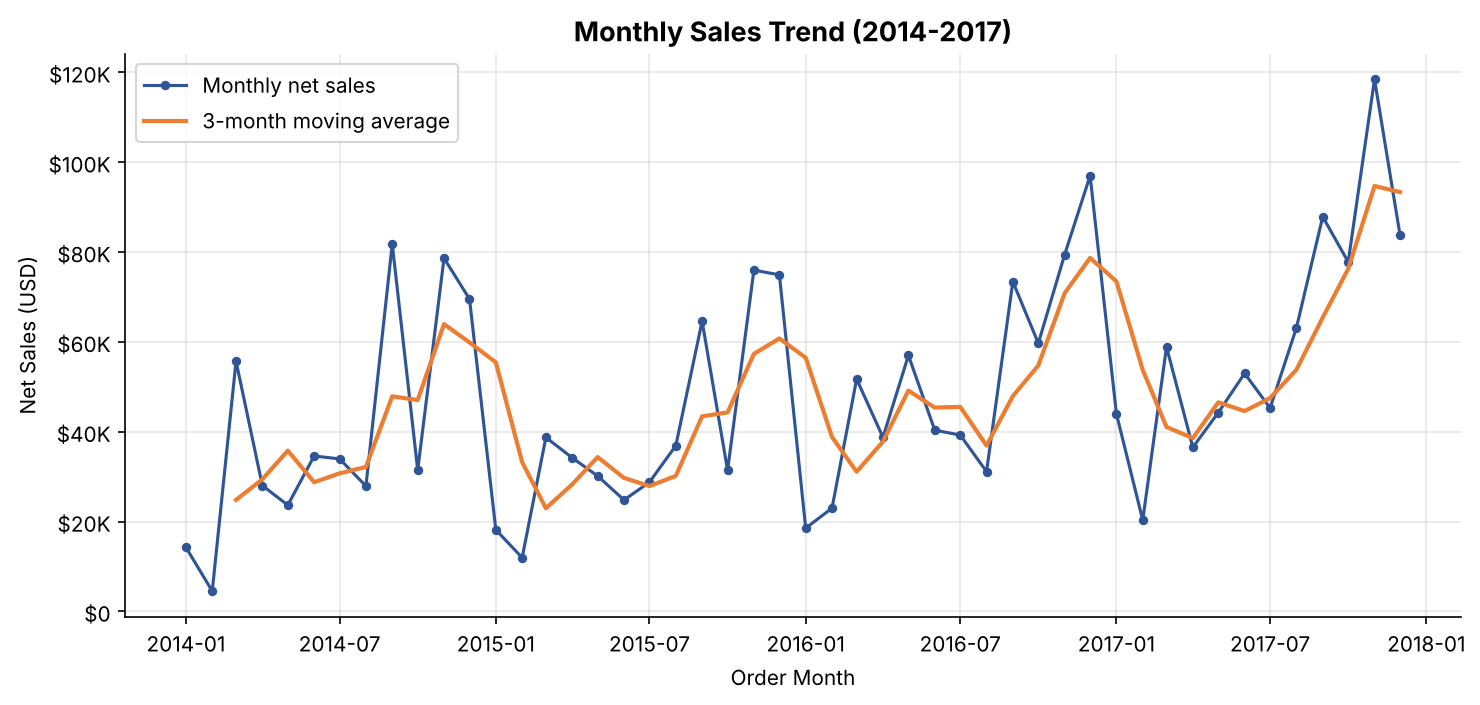

In [19]:
# Chart 1 - Monthly sales trend (line)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(monthly.index, monthly.values, color=PRIMARY, marker="o", markersize=3.5, label="Monthly net sales")
ax.plot(monthly.index, monthly.rolling(3).mean(), color=ACCENT, linewidth=2, label="3-month moving average")
ax.set_title("Monthly Sales Trend (2014-2017)")
ax.set_xlabel("Order Month"); ax.set_ylabel("Net Sales (USD)")
ax.yaxis.set_major_formatter(money); ax.legend()
save_chart(fig, "01_monthly_sales_trend.png")

saved charts/02_sales_by_region.png


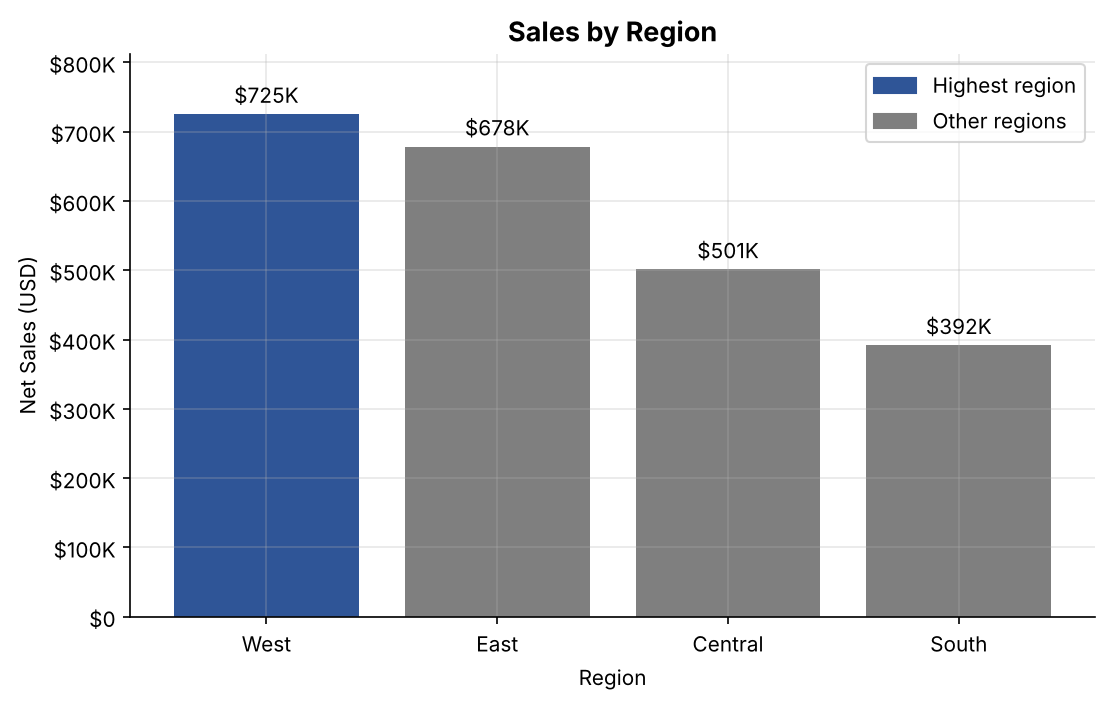

In [20]:
# Chart 2 - Sales by region (bar)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
bars = ax.bar(region_sales.index, region_sales.values, color=[PRIMARY if r == region_sales.idxmax() else GREY for r in region_sales.index])
ax.bar_label(bars, labels=[f"${v/1e3:,.0f}K" for v in region_sales.values], padding=3)
ax.set_title("Sales by Region"); ax.set_xlabel("Region"); ax.set_ylabel("Net Sales (USD)")
ax.yaxis.set_major_formatter(money); ax.set_ylim(0, region_sales.max() * 1.12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PRIMARY), plt.Rectangle((0, 0), 1, 1, color=GREY)], labels=["Highest region", "Other regions"])
save_chart(fig, "02_sales_by_region.png")

saved charts/03_profit_by_category.png


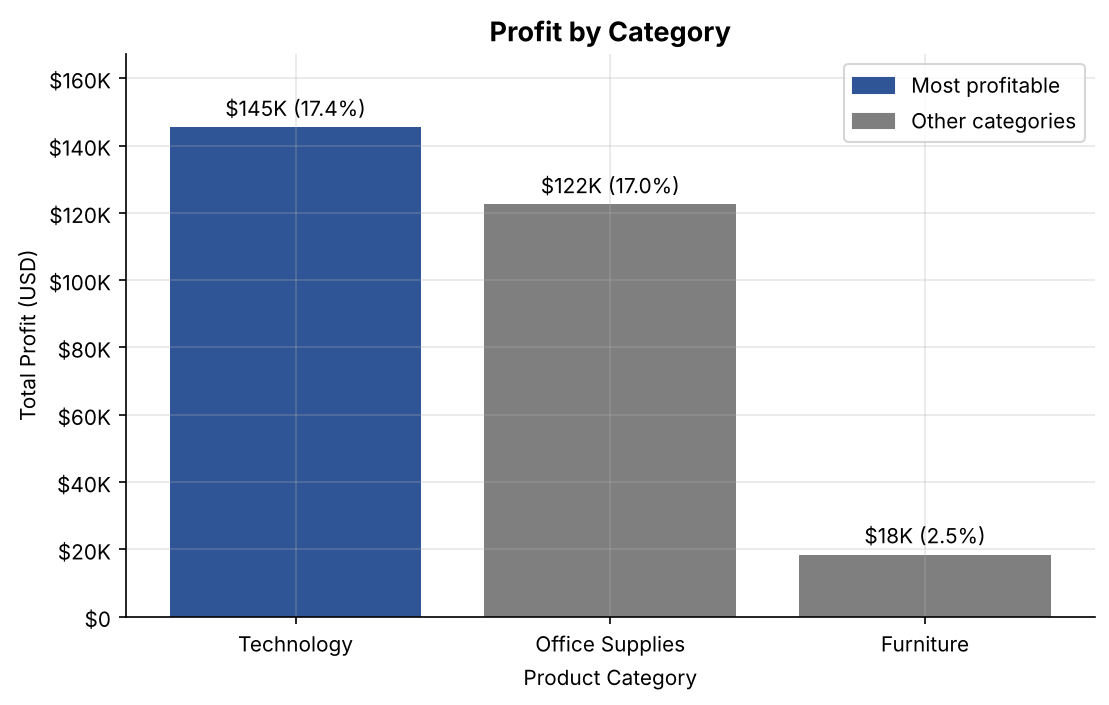

In [21]:
# Chart 3 - Profit by category (bar)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
bars = ax.bar(category_profit.index, category_profit["profit"], color=[PRIMARY if c == category_profit.index[0] else GREY for c in category_profit.index])
ax.bar_label(bars, labels=[f"${v/1e3:,.0f}K ({m:.1f}%)" for v, m in zip(category_profit["profit"], category_profit["margin_pct"])], padding=3)
ax.set_title("Profit by Category"); ax.set_xlabel("Product Category"); ax.set_ylabel("Total Profit (USD)")
ax.yaxis.set_major_formatter(money); ax.set_ylim(0, category_profit["profit"].max() * 1.15)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PRIMARY), plt.Rectangle((0, 0), 1, 1, color=GREY)], labels=["Most profitable", "Other categories"])
save_chart(fig, "03_profit_by_category.png")

saved charts/04_top10_products.png


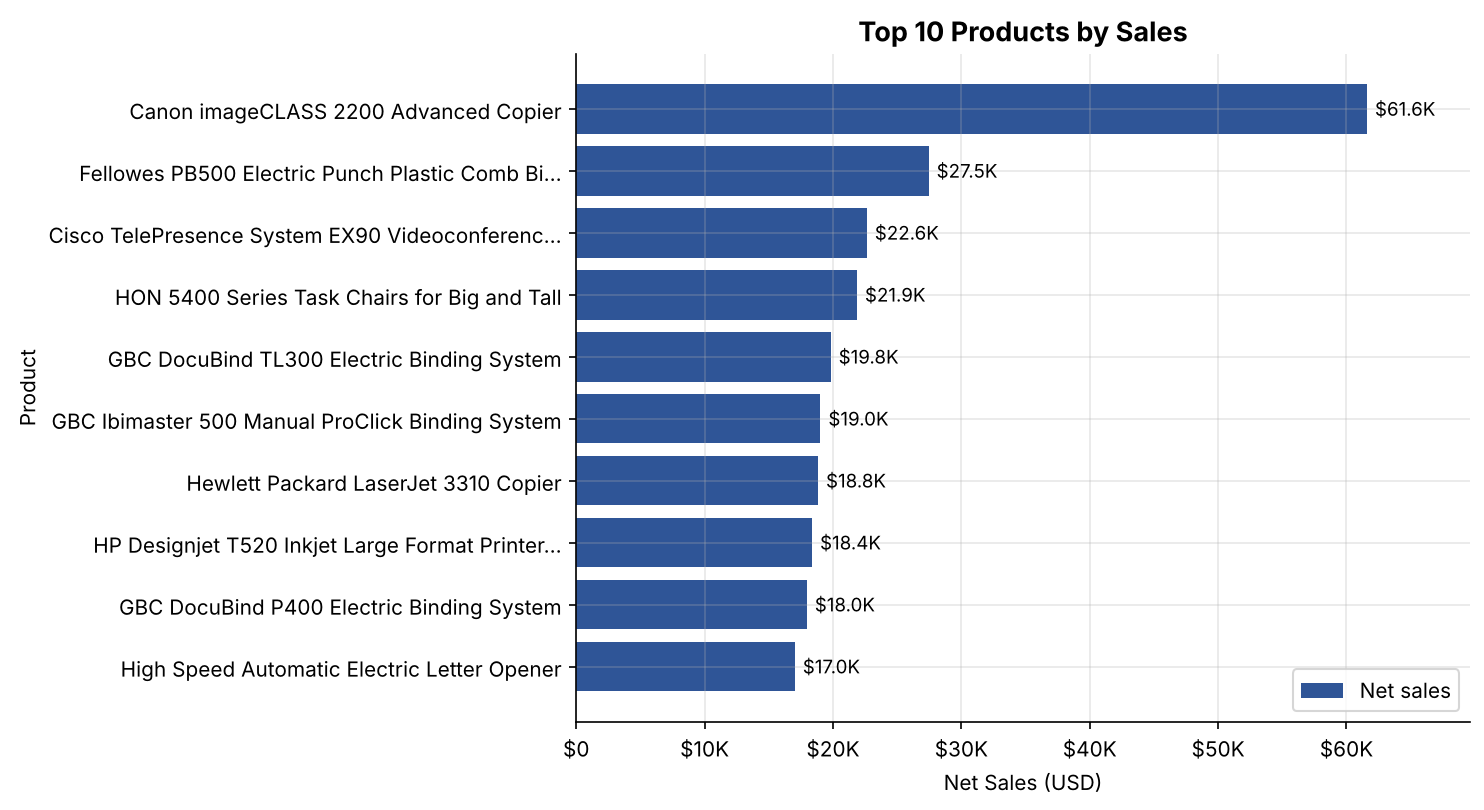

In [22]:
# Chart 4 - Top 10 products by sales (horizontal bar)
fig, ax = plt.subplots(figsize=(10, 5.5))
labels = [n if len(n) <= 48 else n[:45] + "..." for n in top10_products.index]
ax.barh(labels[::-1], top10_products.values[::-1], color=PRIMARY, label="Net sales")
for y, v in enumerate(top10_products.values[::-1]):
    ax.text(v + top10_products.max() * 0.01, y, f"${v/1e3:,.1f}K", va="center", fontsize=9)
ax.set_title("Top 10 Products by Sales"); ax.set_xlabel("Net Sales (USD)"); ax.set_ylabel("Product")
ax.xaxis.set_major_formatter(money); ax.set_xlim(0, top10_products.max() * 1.13); ax.legend(loc="lower right")
save_chart(fig, "04_top10_products.png")

saved charts/05_sales_distribution.png


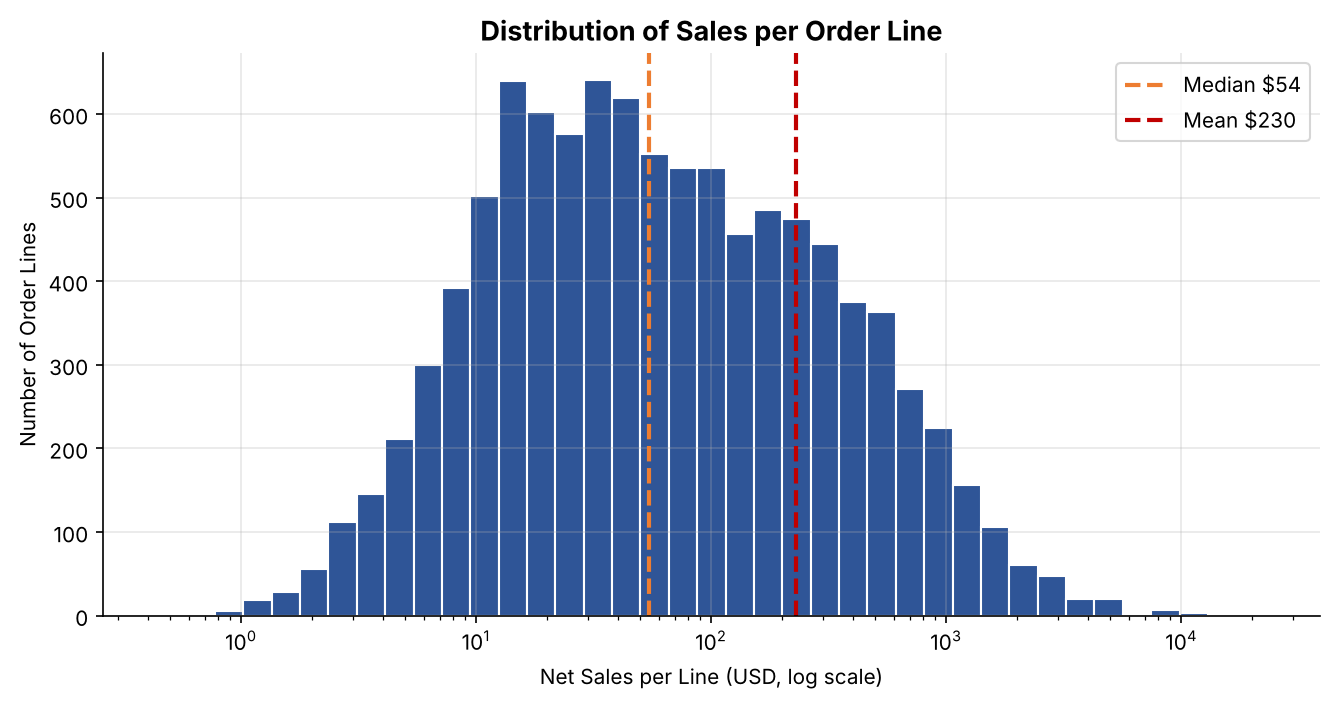

In [23]:
# Chart 5 - Distribution of sales (histogram, log-spaced bins because sales are heavily right-skewed)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(df["net_sales"], bins=np.logspace(np.log10(df["net_sales"].min()), np.log10(df["net_sales"].max()), 40), color=PRIMARY, edgecolor="white")
ax.axvline(df["net_sales"].median(), color=ACCENT, linestyle="--", linewidth=2, label=f"Median ${df['net_sales'].median():,.0f}")
ax.axvline(df["net_sales"].mean(), color="#C00000", linestyle="--", linewidth=2, label=f"Mean ${df['net_sales'].mean():,.0f}")
ax.set_xscale("log")
ax.set_title("Distribution of Sales per Order Line"); ax.set_xlabel("Net Sales per Line (USD, log scale)"); ax.set_ylabel("Number of Order Lines")
ax.legend()
save_chart(fig, "05_sales_distribution.png")

## 8. Save outputs & business insights

In [24]:
df.to_csv(CLEAN_PATH, index=False)
region_sales.to_csv(OUTPUT_DIR / "sales_by_region.csv")
category_profit.to_csv(OUTPUT_DIR / "profit_by_category.csv")
top10_products.to_csv(OUTPUT_DIR / "top10_products.csv")
top10_customers.to_csv(OUTPUT_DIR / "top10_customers.csv")
monthly.rename("net_sales").to_csv(OUTPUT_DIR / "monthly_sales.csv")
yearly.to_csv(OUTPUT_DIR / "yearly_summary.csv")
discount_profit.to_csv(OUTPUT_DIR / "profit_by_discount_band.csv")
print(f"Cleaned dataset saved: {CLEAN_PATH}  ({df.shape[0]:,} rows x {df.shape[1]} columns)")

Cleaned dataset saved: data/superstore_sales_day08_cleaned.csv  (9,993 rows x 26 columns)


In [25]:
total_net, total_profit = df["net_sales"].sum(), df["profit"].sum()
subcat_profit = df.groupby("sub_category", observed=True)["profit"].sum().sort_values()
loss_lines = df[df["profit"] < 0]
print(f"Total net sales ${total_net:,.0f} | profit ${total_profit:,.0f} | margin {total_profit/total_net*100:.1f}%")
print(f"Highest-revenue region: {region_sales.idxmax()} (${region_sales.max():,.0f})")
print(f"Most profitable category: {category_profit.index[0]} (${category_profit['profit'].iloc[0]:,.0f}, {category_profit['margin_pct'].iloc[0]:.1f}% margin)")
print(f"Loss-making lines: {len(loss_lines):,} ({len(loss_lines)/len(df)*100:.1f}%), total loss ${loss_lines['profit'].sum():,.0f}")
print(f"Worst sub-categories by profit: {subcat_profit.head(3).round(0).to_dict()}")
print(f"Lowest-margin region: {(df.groupby('region', observed=True)['profit'].sum()/region_sales).idxmin()}")
print(f"Top 10 customers share of revenue: {top10_customers.sum()/total_net*100:.1f}%")
INSIGHT_FACTS = dict(total_net=total_net, total_profit=total_profit)

Total net sales $2,296,919 | profit $286,409 | margin 12.5%
Highest-revenue region: West ($725,458)
Most profitable category: Technology ($145,455, 17.4% margin)
Loss-making lines: 1,870 (18.7%), total loss $-156,119
Worst sub-categories by profit: {'Tables': -17725.0, 'Bookcases': -3473.0, 'Supplies': -1189.0}
Lowest-margin region: Central
Top 10 customers share of revenue: 6.7%


### Business insights
See `ApexLark_Day08_Business_Analysis_Report.pdf` for the one-page report with the data quality findings, key results and five recommendations.